# Anatomy of a Small Language Model
### Understanding a decoder-only Transformer from the inside — using Python and NumPy

> **Learning objective:** Follow a short sequence of text through the main components of a small decoder-only Transformer, understand the mathematics, and implement a miniature forward pass ourselves.

We will use **Python and NumPy** for the core calculations. Pandas will help inspect token mappings, and Matplotlib will help visualize selected results. We will introduce PyTorch later, when we need automatic differentiation and GPU-accelerated training.

### What this notebook is — and is not

- This is an educational implementation designed to make the computations visible.
- The model uses tiny dimensions and randomly initialized weights so it runs quickly on an ordinary laptop.
- We will implement a **forward pass**, not train a useful language model yet.
- A real SLM requires a tokenizer, a large and carefully prepared corpus, optimization, many training steps, evaluation, and engineering choices beyond this demonstration.

### Notebook map

1. The big picture: what happens inside an SLM?
2. A decoder-only Transformer at a glance
3. Text, tokens, and token IDs
4. Token embeddings
5. Positional information
6. Queries, Keys, and Values
7. Scaled dot-product self-attention
8. Causal masking
9. Multi-head attention
10. Feed-forward network
11. Residual connections and LayerNorm
12. Vocabulary projection, logits, and probabilities
13. Put the pieces together
14. Inspect the complete forward pass
15. What we have built — and what comes next

## 1. The big picture: what happens inside an SLM?

A decoder-only language model receives a sequence of token IDs and produces a score for every possible next token.

For example:

```text
Input text:       The sun rises in the
Token IDs:        [ ... ]
Model output:     scores for every token in its vocabulary
Next-token guess: morning
```

The model does not normally produce an entire paragraph in one operation. It predicts a next token, appends it to the context, and repeats.

For an input sequence \(x_1, x_2, \ldots, x_T\), an autoregressive model represents the sequence probability as:

\[
P(x_1,\ldots,x_T)=\prod_{t=1}^{T}P(x_t\mid x_1,\ldots,x_{t-1})
\]

The key question for this notebook is:

**How does a neural network transform token IDs into next-token scores?**

At a high level:

\[
\text{Token IDs}
\rightarrow \text{Embeddings}
\rightarrow \text{Transformer blocks}
\rightarrow \text{Logits}
\]

We will unpack every stage.

## 2. A decoder-only Transformer at a glance

A simplified decoder-only Transformer has this flow:

```text
Token IDs
   │
   ▼
Token embeddings + positional information
   │
   ▼
Transformer block 1
   ├── Causal self-attention
   ├── Residual connection + normalization
   ├── Feed-forward network
   └── Residual connection + normalization
   │
   ▼
Transformer block 2
   │
   ▼
       ...
   │
   ▼
Final normalization
   │
   ▼
Linear vocabulary projection
   │
   ▼
Logits for the next token
```

A real architecture may arrange normalization and residual operations differently. For example, many modern decoder-only models use **pre-normalization**, where normalization is applied before attention and before the feed-forward network. We will use a clear, common pre-norm layout in our miniature implementation.

### A few dimensions we will use

To keep the examples small:

| Symbol | Meaning | Value in our demo |
|---|---|---:|
| \(B\) | Batch size | 1 |
| \(T\) | Sequence length | 6 |
| \(d_{model}\) | Embedding / hidden size | 16 |
| \(H\) | Number of attention heads | 4 |
| \(d_{head}\) | Dimension per head | 4 |
| \(V\) | Vocabulary size | determined below |

These are **toy dimensions**, not recommended production SLM settings. To keep the NumPy calculations easy to inspect, this notebook omits the batch axis; the examples below use one sequence at a time.

### Imports

We will keep the imports together near the beginning of the notebook.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)

SEED = 42
rng = np.random.default_rng(SEED)

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

NumPy: 2.4.6
Pandas: 3.1.1

## 3. Text, tokens, and token IDs

Neural networks operate on numbers, not raw text. A tokenizer converts text into discrete units called **tokens**, and maps each token to an integer ID.

For learning purposes, we will begin with a tiny word-level tokenizer. This is deliberately simple: modern language models usually use subword or byte-level tokenization methods such as BPE or related algorithms. We will study those separately.

Our example sentence:

```text
the sun rises in the morning
```

A word-level tokenizer splits on spaces. It then assigns each unique token an integer.

### Build a tiny vocabulary

In [3]:
text = "the sun rises in the morning"
tokens = text.split()

vocabulary = sorted(set(tokens))
token_to_id = {token: idx for idx, token in enumerate(vocabulary)}
id_to_token = {idx: token for token, idx in token_to_id.items()}

token_ids = [token_to_id[token] for token in tokens]

vocab_table = pd.DataFrame({
    "token": vocabulary,
    "token_id": [token_to_id[token] for token in vocabulary]
})

display(vocab_table)
print("Tokens:  ", tokens)
print("Token IDs:", token_ids)

,token,token_id
0,in,0
1,morning,1
2,rises,2
3,sun,3
4,the,4


Tokens:   ['the', 'sun', 'rises', 'in', 'the', 'morning']
Token IDs: [4, 3, 2, 0, 4, 1]

### What did we just do?

- The sentence became a list of tokens.
- Each unique token received an integer ID.
- The sentence became a sequence of integer IDs.

The integer IDs are **labels**, not meaningful numerical measurements. For example, token ID 5 is not inherently larger or more important than token ID 2.

In practice, the tokenizer is a separate component. Its vocabulary and rules must be consistent between training and inference.

## 4. Token embeddings: turning IDs into vectors

An integer ID does not contain enough information for a neural network to work with directly. We use an **embedding matrix** to look up a learnable vector for each token.

Let:

- \(V\) = vocabulary size
- \(d_{model}\) = embedding dimension
- \(E\) = embedding matrix

Then:

\[
E \in \mathbb{R}^{V \times d_{model}}
\]

The embedding for token ID \(i\) is simply row \(i\) of the matrix:

\[
e_i = E[i]
\]

For our toy example, we will use 16 numbers per token.

### Create an embedding matrix

In [4]:
vocab_size = len(vocabulary)
d_model = 16

# Random initialization for demonstration.
# During training, these values are learned and updated.
embedding_matrix = rng.normal(
    loc=0.0,
    scale=0.02,
    size=(vocab_size, d_model)
)

token_ids_array = np.array(token_ids, dtype=np.int64)
token_embeddings = embedding_matrix[token_ids_array]

print("Embedding matrix shape:", embedding_matrix.shape)
print("Input token IDs shape: ", token_ids_array.shape)
print("Token embeddings shape:", token_embeddings.shape)
print("\nVector for the first token:")
print(token_embeddings[0])

Embedding matrix shape: (5, 16)
Input token IDs shape:  (6,)
Token embeddings shape: (6, 16)

Vector for the first token:
[ 0.014  0.016 -0.007 -0.009  0.017 -0.004 -0.026 -0.023 -0.018  0.01
  0.003  0.014 -0.009  0.003  0.013 -0.006]

### Understand the shapes

Our input has 6 tokens and each token is represented by 16 numbers.

Therefore:

\[
\text{token\_embeddings} \in \mathbb{R}^{6 \times 16}
\]

Each row corresponds to one token position; each column is one feature in its vector representation.

**Important:** The embedding values are currently random. A trained model learns useful embedding values through optimization.

## 5. Positional information: representing token order

Self-attention, by itself, does not inherently know whether a token appeared first or last. We therefore provide information about token positions.

One classic approach is **sinusoidal positional encoding**. It uses sine and cosine functions at different frequencies.

For position \(pos\) and dimension index \(i\):

\[
PE(pos,2i)=\sin\left(\frac{pos}{10000^{2i/d_{model}}}\right)
\]

\[
PE(pos,2i+1)=\cos\left(\frac{pos}{10000^{2i/d_{model}}}\right)
\]

We will implement this formula. It is useful for learning, although many modern decoder-only models use other approaches, such as Rotary Position Embeddings (RoPE), which we will study later.

### Implement sinusoidal positional encoding

Position encoding shape: (6, 16)

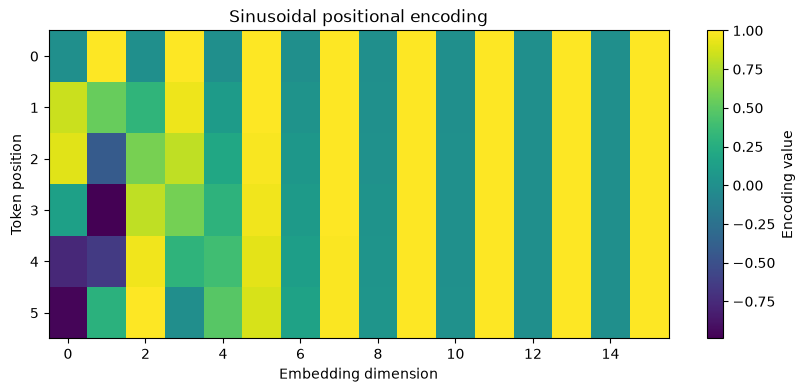

In [5]:
def sinusoidal_positional_encoding(sequence_length, d_model):
    positions = np.arange(sequence_length)[:, np.newaxis]
    dimensions = np.arange(d_model)[np.newaxis, :]

    angle_rates = 1 / np.power(
        10000,
        (2 * (dimensions // 2)) / d_model
    )
    angles = positions * angle_rates

    encoding = np.zeros((sequence_length, d_model))
    encoding[:, 0::2] = np.sin(angles[:, 0::2])
    encoding[:, 1::2] = np.cos(angles[:, 1::2])

    return encoding


sequence_length = len(token_ids)
position_encoding = sinusoidal_positional_encoding(sequence_length, d_model)

print("Position encoding shape:", position_encoding.shape)

plt.figure(figsize=(10, 4))
plt.imshow(position_encoding, aspect="auto", cmap="viridis")
plt.colorbar(label="Encoding value")
plt.xlabel("Embedding dimension")
plt.ylabel("Token position")
plt.title("Sinusoidal positional encoding")
plt.show()

### Combine token and position information

We add the positional encoding to the token embeddings:

\[
X = E_{\text{tokens}} + PE
\]

The shapes must match. Both are `(sequence_length, d_model)`.

This gives the Transformer a representation containing both token identity and position information.

In [6]:
x = token_embeddings + position_encoding

print("Combined representation shape:", x.shape)
print("First token representation after adding position:")
print(x[0])

Combined representation shape: (6, 16)
First token representation after adding position:
[ 0.014  1.016 -0.007  0.991  0.017  0.996 -0.026  0.977 -0.018  1.01
  0.003  1.014 -0.009  1.003  0.013  0.994]

## 6. Queries, Keys, and Values

Self-attention is the mechanism that lets each token position gather information from other positions.

The mechanism uses three learned linear projections:

- **Query (Q):** what information is this position looking for?
- **Key (K):** what information does each position offer for matching?
- **Value (V):** what information is passed along if a position is attended to?

These are useful intuitions, not literal meanings understood by the model.

For an input matrix \(X\):

\[
Q=XW_Q,\quad K=XW_K,\quad V=XW_V
\]

For a single attention head, each projection matrix maps from the model dimension to the head dimension.

Let's create these matrices.

In [7]:
d_head = 4

W_q = rng.normal(0, 0.2, size=(d_model, d_head))
W_k = rng.normal(0, 0.2, size=(d_model, d_head))
W_v = rng.normal(0, 0.2, size=(d_model, d_head))

Q = x @ W_q
K = x @ W_k
V_values = x @ W_v

print("X:", x.shape)
print("Q:", Q.shape)
print("K:", K.shape)
print("V:", V_values.shape)

X: (6, 16)
Q: (6, 4)
K: (6, 4)
V: (6, 4)

Each token position now has a query, key, and value vector.

For a sequence of length \(T\) and head dimension \(d_{head}\), each matrix has shape:

\[
Q,K,V \in \mathbb{R}^{T \times d_{head}}
\]

The next step is to compare queries with keys.

## 7. Scaled dot-product self-attention

For every query position, we calculate similarity scores against all key positions:

\[
S = QK^T
\]

Large dot products indicate stronger alignment between a query and a key. We divide by \(\sqrt{d_{head}}\) to keep score magnitudes more controlled:

\[
S_{\text{scaled}} = \frac{QK^T}{\sqrt{d_{head}}}
\]

We then apply softmax row-wise to turn scores into weights:

\[
A = \operatorname{softmax}(S_{\text{scaled}})
\]

Finally, we use these weights to combine value vectors:

\[
\operatorname{Attention}(Q,K,V)=AV
\]

### First, implement a numerically stable softmax

In [8]:
def softmax(values, axis=-1):
    shifted = values - np.max(values, axis=axis, keepdims=True)
    exp_values = np.exp(shifted)
    return exp_values / np.sum(exp_values, axis=axis, keepdims=True)


def scaled_dot_product_attention(Q, K, V):
    head_dim = Q.shape[-1]
    scores = (Q @ K.T) / np.sqrt(head_dim)
    weights = softmax(scores, axis=-1)
    output = weights @ V
    return output, weights, scores


attention_output, attention_weights, attention_scores = (
    scaled_dot_product_attention(Q, K, V_values)
)

print("Attention scores shape:", attention_scores.shape)
print("Attention weights shape:", attention_weights.shape)
print("Attention output shape:", attention_output.shape)
print("\nAttention weights (each row sums to 1):")
print(attention_weights)
print("Row sums:", attention_weights.sum(axis=-1))

Attention scores shape: (6, 6)
Attention weights shape: (6, 6)
Attention output shape: (6, 4)

Attention weights (each row sums to 1):
[[0.201 0.19  0.168 0.15  0.143 0.148]
 [0.211 0.193 0.164 0.144 0.14  0.148]
 [0.218 0.191 0.159 0.139 0.14  0.152]
 [0.216 0.186 0.155 0.14  0.145 0.158]
 [0.202 0.179 0.157 0.147 0.152 0.163]
 [0.188 0.174 0.16  0.154 0.158 0.165]]
Row sums: [1. 1. 1. 1. 1. 1.]

### Visualize attention weights

Each row represents the attention distribution for one query position. Each column represents a key position.

At this stage, we have not yet applied a causal mask, so every position can attend to every other position — including future positions. That is not allowed for autoregressive generation. We fix that next.

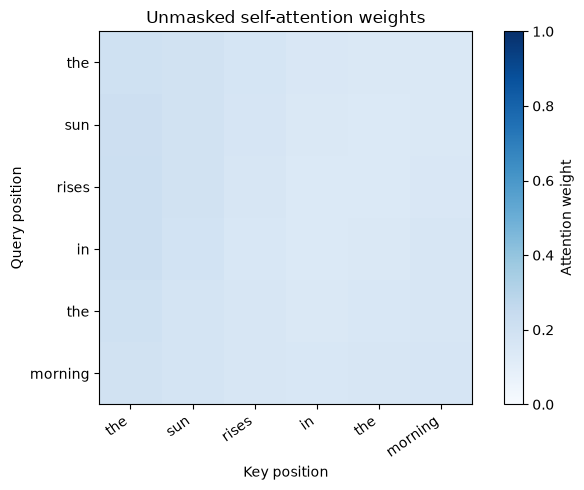

In [9]:
plt.figure(figsize=(7, 5))
plt.imshow(attention_weights, cmap="Blues", vmin=0, vmax=1)
plt.colorbar(label="Attention weight")
plt.xticks(range(sequence_length), tokens, rotation=35, ha="right")
plt.yticks(range(sequence_length), tokens)
plt.xlabel("Key position")
plt.ylabel("Query position")
plt.title("Unmasked self-attention weights")
plt.tight_layout()
plt.show()

## 8. Causal masking: preventing access to future tokens

An autoregressive language model must not use future tokens when predicting the next token.

For example, when processing:

```text
the sun rises in the morning
```

the representation at `sun` must not use `rises`, `in`, or `the morning`.

We enforce this with a **causal mask**. The mask allows a position to attend to itself and earlier positions, but blocks later positions.

We set blocked scores to a very large negative number before softmax. In practical implementations this is often negative infinity.

For a sequence of length 5, the allowed pattern looks like:

```text
1 0 0 0 0
1 1 0 0 0
1 1 1 0 0
1 1 1 1 0
1 1 1 1 1
```

### Implement causal self-attention

In [10]:
def causal_scaled_dot_product_attention(Q, K, V):
    head_dim = Q.shape[-1]
    scores = (Q @ K.T) / np.sqrt(head_dim)

    sequence_length = Q.shape[0]
    future_mask = np.triu(
        np.ones((sequence_length, sequence_length), dtype=bool),
        k=1
    )

    masked_scores = np.where(future_mask, -1e9, scores)
    weights = softmax(masked_scores, axis=-1)
    output = weights @ V

    return output, weights, masked_scores, future_mask


causal_output, causal_weights, causal_scores, future_mask = (
    causal_scaled_dot_product_attention(Q, K, V_values)
)

print("Causal attention weights:")
print(causal_weights)
print("\nRow sums:", causal_weights.sum(axis=-1))

Causal attention weights:
[[1.    0.    0.    0.    0.    0.   ]
 [0.523 0.477 0.    0.    0.    0.   ]
 [0.384 0.337 0.279 0.    0.    0.   ]
 [0.31  0.267 0.223 0.201 0.    0.   ]
 [0.242 0.214 0.187 0.175 0.182 0.   ]
 [0.188 0.174 0.16  0.154 0.158 0.165]]

Row sums: [1. 1. 1. 1. 1. 1.]

### Visualize the causal attention matrix

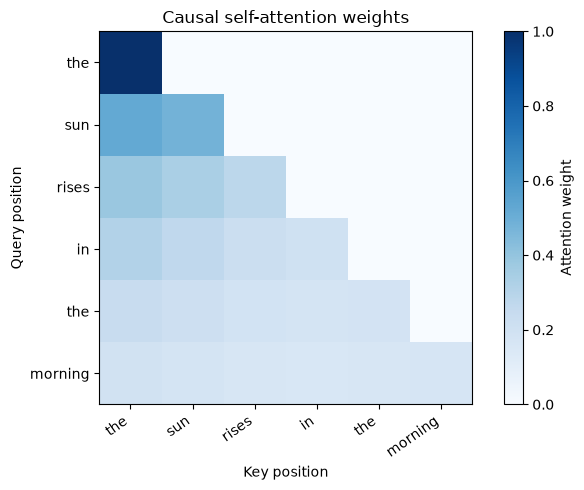

In [11]:
plt.figure(figsize=(7, 5))
plt.imshow(causal_weights, cmap="Blues", vmin=0, vmax=1)
plt.colorbar(label="Attention weight")
plt.xticks(range(sequence_length), tokens, rotation=35, ha="right")
plt.yticks(range(sequence_length), tokens)
plt.xlabel("Key position")
plt.ylabel("Query position")
plt.title("Causal self-attention weights")
plt.tight_layout()
plt.show()

Notice that all positions to the right of the diagonal have zero attention weight.

**Why does this matter?** During training, we can process many positions in parallel while ensuring that the prediction at each position only uses information that would have been available at that point in the sequence.

## 9. Multi-head attention

So far, we have implemented one attention head. **Multi-head attention** runs several attention heads in parallel.

Each head has its own query, key, and value projections. Different heads can learn different patterns of relationships.

If:

- \(d_{model}=16\)
- number of heads \(H=4\)

then a common design is:

\[
d_{head}=\frac{d_{model}}{H}=4
\]

The outputs of all heads are concatenated and projected back to the model dimension.

### Implement multi-head causal self-attention

For clarity, this implementation uses explicit NumPy loops over the heads. Optimized libraries use batched matrix operations instead.

In [12]:
def multi_head_causal_attention(x, num_heads, rng):
    sequence_length, model_dim = x.shape

    if model_dim % num_heads != 0:
        raise ValueError("model_dim must be divisible by num_heads")

    head_dim = model_dim // num_heads
    head_outputs = []
    all_weights = []

    for _ in range(num_heads):
        W_q = rng.normal(0, 0.2, size=(model_dim, head_dim))
        W_k = rng.normal(0, 0.2, size=(model_dim, head_dim))
        W_v = rng.normal(0, 0.2, size=(model_dim, head_dim))

        Q = x @ W_q
        K = x @ W_k
        V = x @ W_v

        head_output, head_weights, _, _ = (
            causal_scaled_dot_product_attention(Q, K, V)
        )

        head_outputs.append(head_output)
        all_weights.append(head_weights)

    concatenated = np.concatenate(head_outputs, axis=-1)

    # Final projection combines information from all heads.
    W_o = rng.normal(0, 0.2, size=(model_dim, model_dim))
    output = concatenated @ W_o

    return output, all_weights


num_heads = 4
mha_output, head_attention_weights = multi_head_causal_attention(
    x, num_heads, rng
)

print("Input shape:               ", x.shape)
print("Number of heads:           ", num_heads)
print("Dimension per head:        ", d_model // num_heads)
print("Number of attention maps:  ", len(head_attention_weights))
print("Multi-head output shape:   ", mha_output.shape)

Input shape:                (6, 16)
Number of heads:            4
Dimension per head:         4
Number of attention maps:   4
Multi-head output shape:    (6, 16)

### Inspect the heads

Each head produces its own attention map. The maps may look different because each head has different learned projections.

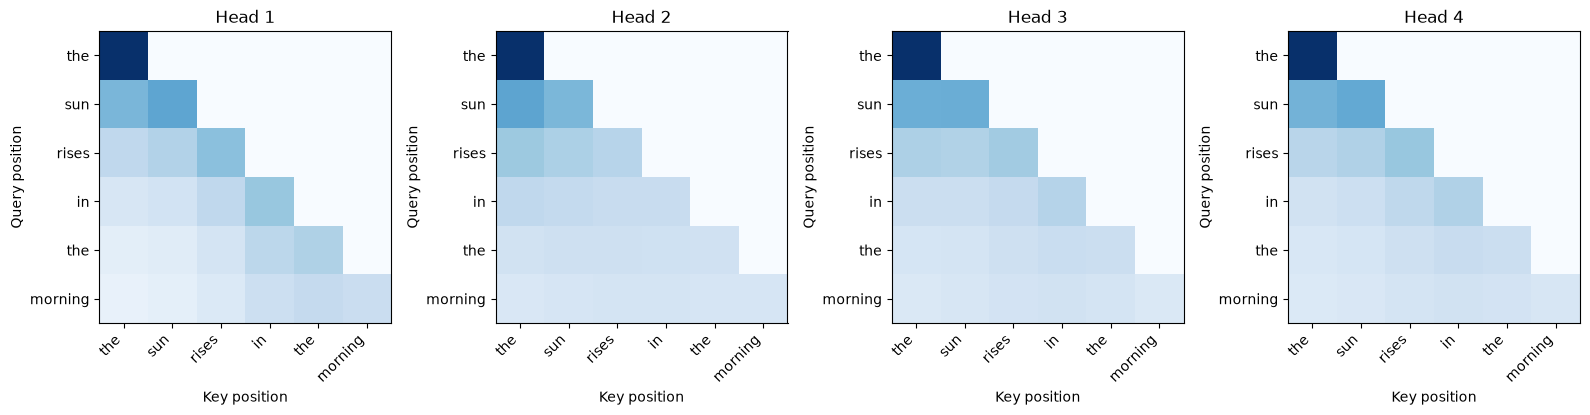

In [13]:
fig, axes = plt.subplots(1, num_heads, figsize=(4 * num_heads, 4))

for head_index, ax in enumerate(axes):
    ax.imshow(head_attention_weights[head_index], cmap="Blues", vmin=0, vmax=1)
    ax.set_title(f"Head {head_index + 1}")
    ax.set_xlabel("Key position")
    ax.set_ylabel("Query position")
    ax.set_xticks(range(sequence_length))
    ax.set_yticks(range(sequence_length))
    ax.set_xticklabels(tokens, rotation=45, ha="right")
    ax.set_yticklabels(tokens)

plt.tight_layout()
plt.show()

## 10. Feed-forward network

After attention, each token position passes through a feed-forward network (FFN).

A simplified two-layer FFN is:

\[
\operatorname{FFN}(x)=\sigma(xW_1+b_1)W_2+b_2
\]

where \(\sigma\) is a nonlinear activation function. We will use ReLU for this first demonstration:

\[
\operatorname{ReLU}(z)=\max(0,z)
\]

The FFN operates independently at each sequence position, using the same weights at every position. Attention mixes information across positions; the FFN transforms the features at each position.

### Implement a simple FFN

In [14]:
def relu(z):
    return np.maximum(0, z)


def feed_forward(x, hidden_dim, rng):
    model_dim = x.shape[-1]

    W1 = rng.normal(0, 0.2, size=(model_dim, hidden_dim))
    b1 = np.zeros(hidden_dim)

    W2 = rng.normal(0, 0.2, size=(hidden_dim, model_dim))
    b2 = np.zeros(model_dim)

    hidden = relu(x @ W1 + b1)
    output = hidden @ W2 + b2

    return output, hidden


ffn_output, ffn_hidden = feed_forward(
    mha_output,
    hidden_dim=4 * d_model,
    rng=rng
)

print("FFN hidden representation:", ffn_hidden.shape)
print("FFN output:               ", ffn_output.shape)

FFN hidden representation: (6, 64)
FFN output:                (6, 16)

In many modern language models, the FFN uses a gated activation such as SwiGLU rather than a basic ReLU. We will study those architectural choices later.

## 11. Residual connections and LayerNorm

Deep networks can be difficult to optimize. Transformer blocks use **residual connections** to provide a direct path for information and gradients.

A residual addition has the form:

\[
y=x+F(x)
\]

Layer normalization normalizes the features within each token representation.

For a vector \(x\):

\[
\operatorname{LayerNorm}(x)=
\frac{x-\mu}{\sqrt{\sigma^2+\epsilon}}\odot\gamma+\beta
\]

Here, \(\gamma\) and \(\beta\) are learnable scale and shift parameters. In this educational NumPy implementation, we will use fixed initial values \(\gamma=1\) and \(\beta=0\).

### Implement LayerNorm

In [15]:
def layer_norm(x, eps=1e-5):
    mean = np.mean(x, axis=-1, keepdims=True)
    variance = np.var(x, axis=-1, keepdims=True)
    normalized = (x - mean) / np.sqrt(variance + eps)
    return normalized


sample_vector = x[0]
normalized_vector = layer_norm(sample_vector)

print("Original mean:    ", sample_vector.mean())
print("Original variance:", sample_vector.var())
print("Normalized mean:  ", normalized_vector.mean())
print("Normalized var:   ", normalized_vector.var())

Original mean:     0.49926168177036456
Original variance: 0.2510318662888568
Normalized mean:   1.3877787807814457e-17
Normalized var:    0.9999601660067785

### A pre-normalization Transformer block

A common modern layout is:

\[
x' = x + \operatorname{Attention}(\operatorname{LayerNorm}(x))
\]

\[
y = x' + \operatorname{FFN}(\operatorname{LayerNorm}(x'))
\]

This is called a **pre-norm** arrangement because normalization happens before each sublayer.

We will assemble one small block using the functions already written. The attention and FFN weights are randomly initialized for this demonstration.

In [16]:
def transformer_block(x, num_heads, rng):
    # Attention sublayer: pre-normalization, attention, residual addition
    normalized_x = layer_norm(x)
    attention_result, attention_maps = multi_head_causal_attention(
        normalized_x, num_heads, rng
    )
    x = x + attention_result

    # Feed-forward sublayer: pre-normalization, FFN, residual addition
    normalized_x = layer_norm(x)
    ffn_result, _ = feed_forward(
        normalized_x, hidden_dim=4 * x.shape[-1], rng=rng
    )
    x = x + ffn_result

    return x, attention_maps


block_output, block_attention_maps = transformer_block(
    x, num_heads=4, rng=rng
)

print("Block input shape: ", x.shape)
print("Block output shape:", block_output.shape)

Block input shape:  (6, 16)
Block output shape: (6, 16)

## 12. Vocabulary projection, logits, and probabilities

After the Transformer blocks, each position has a contextual representation of size \(d_{model}\).

To predict a token, we project that representation into vocabulary space:

\[
\text{logits}=hW_{\text{vocab}}+b
\]

If the vocabulary has \(V\) tokens, the logits vector has \(V\) values.

These values are called **logits**. They are unnormalized scores, not probabilities.

Softmax converts logits into a probability distribution:

\[
P(x_i)=\frac{e^{z_i}}{\sum_j e^{z_j}}
\]

### Project the final position into vocabulary space

For next-token prediction, we use the representation at the final input position.

In [17]:
# Final normalization (using our simple LayerNorm)
final_representations = layer_norm(block_output)

# Vocabulary projection
W_vocab = rng.normal(
    0, 0.2, size=(d_model, vocab_size)
)
b_vocab = np.zeros(vocab_size)

# Use the last position to predict the next token
last_hidden_state = final_representations[-1]
logits = last_hidden_state @ W_vocab + b_vocab
next_token_probabilities = softmax(logits)

prediction_table = pd.DataFrame({
    "token": vocabulary,
    "logit": logits,
    "probability": next_token_probabilities
}).sort_values("probability", ascending=False)

display(prediction_table)
print("Probability sum:", next_token_probabilities.sum())

,token,logit,probability
2,rises,-0.367705,0.334924
1,morning,-0.896966,0.197284
3,sun,-1.007887,0.176571
0,in,-1.138474,0.154955
4,the,-1.267002,0.136266


Probability sum: 1.0

The predicted token is the token with the highest probability if we use greedy decoding. Other decoding strategies can sample from the distribution.

Remember: these probabilities are **not meaningful language predictions**. Our weights are random and the model has not been trained. We are demonstrating the data flow and mathematics, not claiming language understanding.

## 13. Put the pieces together: a miniature Transformer forward pass

We can now connect the operations into one compact model.

This model contains:
- A token embedding lookup
- Sinusoidal positional encoding
- One decoder-style Transformer block
- A vocabulary projection

It uses random parameters and is for forward-pass education only. We will deliberately keep the code readable rather than optimizing it.

In [18]:
class MiniTransformer:
    def __init__(
        self,
        vocab_size,
        d_model=16,
        num_heads=4,
        seed=123
    ):
        if d_model % num_heads != 0:
            raise ValueError("d_model must be divisible by num_heads")

        self.vocab_size = vocab_size
        self.d_model = d_model
        self.num_heads = num_heads
        self.rng = np.random.default_rng(seed)
        # Our helper functions draw their weights from an RNG when called. Re-seeding the
        # same RNG on every forward pass makes the block's weights identical on every call,
        # so this behaves like one model with fixed parameters.
        self.block_seed = seed + 1

        self.token_embedding = self.rng.normal(
            0, 0.02, size=(vocab_size, d_model)
        )

        self.W_vocab = self.rng.normal(
            0, 0.2, size=(d_model, vocab_size)
        )
        self.b_vocab = np.zeros(vocab_size)

    def forward(self, input_ids):
        input_ids = np.asarray(input_ids, dtype=np.int64)

        # 1. Token embedding
        x = self.token_embedding[input_ids]

        # 2. Positional information
        positions = sinusoidal_positional_encoding(
            len(input_ids), self.d_model
        )
        x = x + positions

        # 3. One Transformer block
        block_rng = np.random.default_rng(self.block_seed)
        x, attention_maps = transformer_block(
            x, self.num_heads, block_rng
        )

        # 4. Final normalization
        x = layer_norm(x)

        # 5. Vocabulary projection at every position
        logits = x @ self.W_vocab + self.b_vocab

        return logits, attention_maps


model = MiniTransformer(
    vocab_size=vocab_size,
    d_model=16,
    num_heads=4
)

model_logits, model_attention_maps = model.forward(token_ids_array)

print("Input IDs shape: ", token_ids_array.shape)
print("Logits shape:    ", model_logits.shape)
print("Expected shape:  ", (sequence_length, vocab_size))

# A model has fixed parameters: the same input must always give the same logits.
repeat_logits, _ = model.forward(token_ids_array)
print("Deterministic forward pass:", np.array_equal(model_logits, repeat_logits))

Input IDs shape:  (6,)
Logits shape:     (6, 5)
Expected shape:   (6, 5)
Deterministic forward pass: True

### Why do we get one logits vector per input position?

The model produces a vocabulary-sized logits vector at every sequence position.

For a training sequence:

```text
the | sun | rises | in | the | morning
```

the causal model is trained to predict the next token at each position:

```text
Input position:  the   sun   rises   in   the
Target token:    sun   rises in      the  morning
```

The final position in a complete training example predicts the token that follows the input window. During inference, we commonly take the logits at the final position to choose the next token.

We will study the exact shifting of inputs and targets, and the next-token training objective, in the pretraining notebook.

## 14. Inspect the complete forward pass

Let's make the data shapes explicit. This is one of the most useful habits when learning Transformer architectures.

For our current input:

| Stage | Shape |
|---|---|
| Input token IDs | `(T,)` |
| Token embeddings | `(T, d_model)` |
| Positional encoding | `(T, d_model)` |
| Combined representation | `(T, d_model)` |
| Each attention head's Q/K/V | `(T, d_head)` |
| Concatenated multi-head output | `(T, d_model)` |
| FFN output | `(T, d_model)` |
| Final hidden representation | `(T, d_model)` |
| Logits | `(T, vocab_size)` |

Let's verify the most important dimensions directly.

In [19]:
shape_summary = pd.DataFrame([
    ("Input token IDs", token_ids_array.shape),
    ("Token embeddings", token_embeddings.shape),
    ("Positional encoding", position_encoding.shape),
    ("Combined input", x.shape),
    ("Single-head Q", Q.shape),
    ("Single-head K", K.shape),
    ("Single-head V", V_values.shape),
    ("Single-head attention output", attention_output.shape),
    ("Multi-head attention output", mha_output.shape),
    ("FFN output", ffn_output.shape),
    ("Transformer block output", block_output.shape),
    ("Final logits", model_logits.shape),
], columns=["Stage", "Shape"])

display(shape_summary)

,Stage,Shape
0,Input token IDs,"(6,)"
1,Token embeddings,"(6, 16)"
2,Positional encoding,"(6, 16)"
3,Combined input,"(6, 16)"
4,Single-head Q,"(6, 4)"
5,Single-head K,"(6, 4)"
6,Single-head V,"(6, 4)"
7,Single-head attention output,"(6, 4)"
8,Multi-head attention output,"(6, 16)"
9,FFN output,"(6, 16)"


## 15. What we have built — and what comes next

We have implemented the major computations of a simplified decoder-only Transformer using NumPy:

- Token-to-vector lookup
- Positional encoding
- Query, Key, and Value projections
- Scaled dot-product attention
- Causal masking
- Multi-head attention
- Feed-forward transformation
- Residual connections
- Layer normalization
- Vocabulary projection
- Softmax probabilities

### Important limitations of this notebook

This is not yet a trainable SLM in the practical sense:

1. The tokenizer is a tiny word-level demonstration, not a production tokenizer.
2. The model weights are randomly initialized.
3. We have not implemented backpropagation or an optimizer.
4. We used one small Transformer block.
5. We used sinusoidal positions and a simple ReLU FFN for clarity.
6. We did not train on a corpus or evaluate language-model quality.

These are deliberate simplifications. We are learning the architecture before building a training system.

### Knowledge check

Try answering these without looking back:

1. Why do we convert token IDs into embeddings?
2. Why does a decoder-only language model need a causal mask?
3. What are the roles of Query, Key, and Value?
4. Why do we divide attention scores by \(\sqrt{d_{head}}\)?
5. What is the difference between logits and probabilities?
6. Why does the model produce a vocabulary-sized output?
7. What does the residual connection add to a Transformer block?

### Next topic

**Tokenization in depth — from text to subword tokens.**

We will understand why word-level tokenization is insufficient for real-world language models, explore vocabulary design and Byte Pair Encoding (BPE), and eventually train our own tokenizer.